# Non-linear static analysis with the Newton-Raphson method

This example solves a geometrically non-linear problem deep in the postbuckling regime with a full Newton-Raphson method written in a few lines. It then checks that the tangent stiffness matrix is the exact derivative of the internal force vector, which makes the method converge quadratically.

The geometrically non-linear models provide the internal force vector $\boldsymbol{F}_{int}(\boldsymbol{c})$, `Shell.calc_fint`, and the tangent stiffness matrix

$$
\boldsymbol{K}_T = \frac{\partial \boldsymbol{F}_{int}}{\partial \boldsymbol{c}} = \boldsymbol{K}_C + \boldsymbol{K}_G,
$$

`Shell.calc_kT`, or `Shell.calc_kC` plus `Shell.calc_kG` with the current $\boldsymbol{c}$. Equilibrium is the root of the residual $\boldsymbol{R}(\boldsymbol{c}) = \boldsymbol{F}_{int}(\boldsymbol{c}) - \boldsymbol{F}_{ext}$. Each Newton-Raphson iteration solves the linearized system

$$
\boldsymbol{K}_T(\boldsymbol{c}_k)\, \Delta\boldsymbol{c} = -\boldsymbol{R}(\boldsymbol{c}_k), \qquad \boldsymbol{c}_{k+1} = \boldsymbol{c}_k + \Delta\boldsymbol{c}.
$$

Near the solution the error of the next iteration is proportional to the square of the current one, $e_{k+1} \approx C e_k^2$, only when $\boldsymbol{K}_T$ is the exact derivative of $\boldsymbol{F}_{int}$. See also [Tangent stiffness matrix and its product by a vector](../tangent_product.rst).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import solve
from panels import modelDB
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Plate and load

The plate of $4 \times 1$ m, laminate $[90/0/90/0]$ of plies of 0.125 mm ($a/h = 8000$), is compressed by $N_{xx} = 700$ N/m along $x = a$. That is about 37 times its first linear buckling load. $w$ is constrained at the four edges, $u$ at $x = 0$ and $v$ at $y = 0$; the other in-plane displacements are free. A small point force of $10^{-3}$ N at the center, `cte=True`, is a perturbation that selects the postbuckling branch.

In [2]:
def build_plate(model):
    E11 = 142.5e9
    E22 = E11/20
    G12 = 0.5*E22
    s = Shell(model=model, a=4., b=1., r=1.e15, m=6, n=6, plyt=0.125e-3,
              stack=[90, 0, 90, 0], laminaprop=(E11, E22, 0.25, G12, G12, G12))
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for field in 'uvw':
            setattr(s, edge + field, 1)
            setattr(s, edge + field + 'r', 1)
        setattr(s, edge + 'w', 0)
    s.x1u = 0
    s.y1v = 0
    s.add_distr_load_fixed_x(s.a, funcx=lambda y: -700./s.b, funcy=None,
                             funcz=None, cte=False)
    s.add_point_load(s.a/2., s.b/2., 0, 0, 0.001, cte=True)
    return s

## Newton-Raphson iterations

The iterations start from the linear solution $\boldsymbol{K}_C \boldsymbol{c}_0 = \boldsymbol{F}_{ext}$ and apply the full load in a single step. Convergence is measured by Crisfield's criterion: the norm of the residual relative to the larger of the norms of $\boldsymbol{F}_{ext}$ and $\boldsymbol{F}_{int}$. Each norm is scaled by the diagonal $\boldsymbol{D}$ of $\boldsymbol{K}_C$, $\|\boldsymbol{v}\|_D = \sqrt{\boldsymbol{v}^\top |\boldsymbol{D}|^{-1} \boldsymbol{v}}$, without the null entries of $\boldsymbol{D}$ (constrained terms).

In [3]:
def scaled_norm(vec, D):
    keep = ~np.isclose(D, 0)
    return np.sqrt((vec[keep]/np.abs(D[keep])) @ vec[keep])


def newton_raphson(s, tol=1.e-10, maxiter=30):
    fext = s.calc_fext()
    kC = s.calc_kC()
    c = solve(kC, fext, silent=True)
    c_lin = c.copy()
    D = kC.diagonal()
    errors = []
    while True:
        R = s.calc_fint(c=c) - fext
        fint = R + fext
        errors.append(scaled_norm(R, D)/max(scaled_norm(fext, D),
                                            scaled_norm(fint, D)))
        if errors[-1] < tol or len(errors) > maxiter:
            break
        c = c + solve(s.calc_kT(c=c), -R, silent=True)
    return c_lin, c, errors


s = build_plate('plate_clpt_donnell')
c_lin, c, errors = newton_raphson(s)
for k, e in enumerate(errors):
    print('iteration %2d, Crisfield criterion %.3e' % (k, e))
orders = [np.log(e1)/np.log(e0) for e0, e1 in zip(errors[:-1], errors[1:])
          if 1.e-15 < e1 and e0 < 1.e-2]
print('convergence orders log(e_k+1)/log(e_k) in the asymptotic range:',
      np.round(orders, 3))

iteration  0, Crisfield criterion 9.832e-01
iteration  1, Crisfield criterion 6.213e-01
iteration  2, Crisfield criterion 9.994e-01
iteration  3, Crisfield criterion 2.552e-01
iteration  4, Crisfield criterion 6.138e-01
iteration  5, Crisfield criterion 5.155e-02
iteration  6, Crisfield criterion 2.032e-02
iteration  7, Crisfield criterion 1.330e-04
iteration  8, Crisfield criterion 8.177e-08
iteration  9, Crisfield criterion 2.354e-14
convergence orders log(e_k+1)/log(e_k) in the asymptotic range: [1.828 1.923]


In the first iterations the solution moves from the linear to the postbuckled configuration and the error does not decrease steadily. Once it is small, the number of correct digits roughly doubles at each iteration:

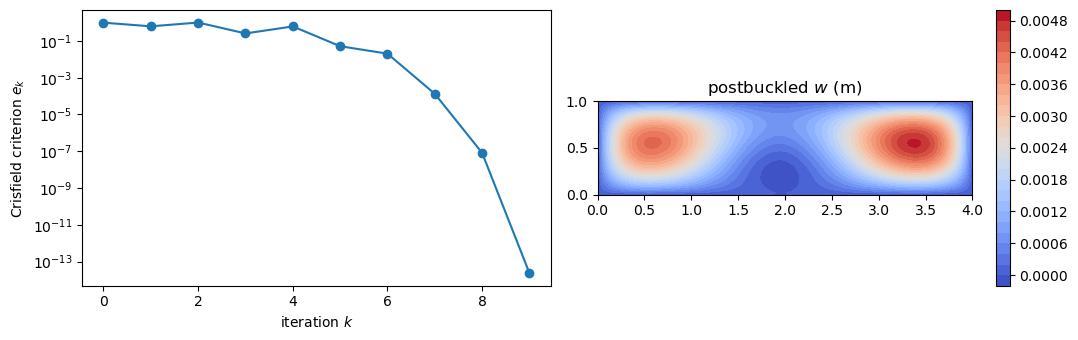

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].semilogy(errors, 'o-')
axes[0].set_xlabel('iteration $k$')
axes[0].set_ylabel('Crisfield criterion $e_k$')
mesh, fields = s.uvw(c, gridx=161, gridy=41)
cf = axes[1].contourf(mesh['Xs'], mesh['Ys'], fields['w'], levels=30,
                      cmap='coolwarm')
fig.colorbar(cf, ax=axes[1])
axes[1].set_title('postbuckled $w$ (m)')
axes[1].set_aspect('equal')
fig.tight_layout()
plt.show()

## Five models

The same analysis with the plate and cylindrical-shell (radius $10^{15}$ m) models of the CLPT, and with the FSDT and TSDT plates. The reference values are those of the panels unit test `tests/tests_shell/test_nonlinear.py`, checked there within 1%. The non-linear one is the deflection on the branch reached by a load-controlled path-following analysis with a secant predictor, which returns the same value with 40, 80 and 160 load increments.

In [5]:
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders', 'plate_fsdt_donnell',
              'plate_tsdt_donnell']:
    s = build_plate(model)
    c_lin, c, errors = newton_raphson(s)
    wlin = s.uvw(c=c_lin)[1]['w'].max()
    wnl = s.uvw(c=c)[1]['w'].max()
    print('%-22s linear max w %.6e m, non-linear max w %.6e m, %d iterations'
          % (model, wlin, wnl, len(errors) - 1))
    rows.append(('`%s`, linear max $w$ (m)' % model, wlin, 0.0026619,
                 'regression value, `test_nonlinear.py`'))
    rows.append(('`%s`, non-linear max $w$ (m)' % model, wnl, 0.004841,
                 'path-following value, `test_nonlinear.py`'))
results_table(rows)

plate_clpt_donnell     linear max w 2.661901e-03 m, non-linear max w 4.841392e-03 m, 9 iterations


cylshell_clpt_donnell  linear max w 2.661901e-03 m, non-linear max w 4.841392e-03 m, 9 iterations


cylshell_clpt_sanders  linear max w 2.661901e-03 m, non-linear max w 4.841392e-03 m, 9 iterations


plate_fsdt_donnell     linear max w 2.661888e-03 m, non-linear max w 4.841394e-03 m, 9 iterations


plate_tsdt_donnell     linear max w 2.661894e-03 m, non-linear max w 4.841394e-03 m, 9 iterations


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, linear max $w$ (m) | 0.0026619 | 0.0026619 | +2.25e-07 | regression value, `test_nonlinear.py` |
| `plate_clpt_donnell`, non-linear max $w$ (m) | 0.00484139 | 0.004841 | +8.09e-05 | path-following value, `test_nonlinear.py` |
| `cylshell_clpt_donnell`, linear max $w$ (m) | 0.0026619 | 0.0026619 | +2.25e-07 | regression value, `test_nonlinear.py` |
| `cylshell_clpt_donnell`, non-linear max $w$ (m) | 0.00484139 | 0.004841 | +8.09e-05 | path-following value, `test_nonlinear.py` |
| `cylshell_clpt_sanders`, linear max $w$ (m) | 0.0026619 | 0.0026619 | +2.25e-07 | regression value, `test_nonlinear.py` |
| `cylshell_clpt_sanders`, non-linear max $w$ (m) | 0.00484139 | 0.004841 | +8.09e-05 | path-following value, `test_nonlinear.py` |
| `plate_fsdt_donnell`, linear max $w$ (m) | 0.00266189 | 0.0026619 | -4.49e-06 | regression value, `test_nonlinear.py` |
| `plate_fsdt_donnell`, non-linear max $w$ (m) | 0.00484139 | 0.004841 | +8.14e-05 | path-following value, `test_nonlinear.py` |
| `plate_tsdt_donnell`, linear max $w$ (m) | 0.00266189 | 0.0026619 | -2.33e-06 | regression value, `test_nonlinear.py` |
| `plate_tsdt_donnell`, non-linear max $w$ (m) | 0.00484139 | 0.004841 | +8.13e-05 | path-following value, `test_nonlinear.py` |

For the shear deformation theories the residual reaches its round-off floor within the asymptotic range, because the plate is very thin. That floor is of the order of $\epsilon (G/E)(a/h)^2 \approx 10^{-9}$, with $\epsilon$ the machine precision. Their order of convergence is better measured by the directional test below.

## Consistency of the tangent stiffness matrix

The Taylor expansion of $\boldsymbol{F}_{int}$ about a state $\boldsymbol{c}$ along a direction $\boldsymbol{d}$,

$$
\boldsymbol{F}_{int}(\boldsymbol{c} + h\boldsymbol{d}) = \boldsymbol{F}_{int}(\boldsymbol{c}) + h \boldsymbol{K}_T(\boldsymbol{c})\boldsymbol{d} + O(h^2),
$$

gives the relative error $e(h) = \|\boldsymbol{F}_{int}(\boldsymbol{c} + h\boldsymbol{d}) - \boldsymbol{F}_{int}(\boldsymbol{c}) - h\boldsymbol{K}_T\boldsymbol{d}\| / (h \|\boldsymbol{K}_T\boldsymbol{d}\|)$. It decreases linearly with $h$, a factor of ten per decade, when $\boldsymbol{K}_T$ is the exact derivative. An inconsistent tangent leaves a first-order remainder, and $e(h)$ stops decreasing.

The state and the direction are random, with large deflections. The panel of $0.3 \times 0.2$ m has the unsymmetric and unbalanced laminate $[30/-45/0/90]$, so $A_{16}$, $A_{26}$ and $\boldsymbol{B}$ are not zero, and all the terms of the kinematics are exercised. Cylindrical shells have $r = 0.4$ m. The test covers the eleven non-linear models, including the Green-Lagrange (`plate_clpt_gl`) and total Lagrangian (`plate_clpt_tl`) plates.

In [6]:
MODELS = ['plate_clpt_donnell', 'cylshell_clpt_donnell',
          'cylshell_clpt_sanders', 'plate_fsdt_donnell', 'plate_tsdt_donnell',
          'cylshell_fsdt_donnell', 'cylshell_fsdt_sanders',
          'cylshell_tsdt_donnell', 'cylshell_tsdt_sanders', 'plate_clpt_gl',
          'plate_clpt_tl']


def make_shell(model):
    E11 = 142.5e9
    E22 = E11/20
    G12 = 0.5*E22
    s = Shell(model=model, a=0.3, b=0.2, m=5, n=5, plyt=0.125e-3,
              stack=[30, -45, 0, 90], laminaprop=(E11, E22, 0.25, G12, G12, G12),
              r=0.4 if model.startswith('cylshell') else None)
    s.nx = s.ny = 8
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for field in 'uvw':
            setattr(s, edge + field, 0. if field == 'w' else 1.)
            setattr(s, edge + field + 'r', 1.)
    s.x1u = 0.
    s.y1v = 0.
    return s


def random_state(s, rng):
    h_shell = len(s.stack)*s.plyt
    c = h_shell*rng.standard_normal(s.get_size())
    dofs = modelDB.db[s.model]['dofs']
    c[2::dofs] *= 20  # w, deflections of the order of 20 thicknesses
    if dofs == 5:
        # rotations of the shear deformation theories, of the order of the
        # slopes of w
        c[3::dofs] *= 20/min(s.a, s.b)
        c[4::dofs] *= 20/min(s.a, s.b)
    return c


steps = np.array([1.e-2, 1.e-3, 1.e-4, 1.e-5, 1.e-6])
taylor = {}
rng = np.random.default_rng(0)
for model in MODELS:
    s = make_shell(model)
    c = random_state(s, rng)
    d = random_state(s, rng)
    f0 = s.calc_fint(c=c)
    KTd = s.calc_kT(c=c) @ d
    taylor[model] = np.array([np.linalg.norm(s.calc_fint(c=c + h*d) - f0
                                             - h*KTd)/(h*np.linalg.norm(KTd))
                              for h in steps])
    slope = np.polyfit(np.log10(steps), np.log10(taylor[model]), 1)[0]
    print('%-22s e(h) = %s, slope %.3f' % (model, np.array2string(
          taylor[model], precision=2), slope))

plate_clpt_donnell     e(h) = [1.63e-04 1.63e-05 1.63e-06 1.63e-07 1.65e-08], slope 0.999
cylshell_clpt_donnell  e(h) = [2.82e-05 2.82e-06 2.82e-07 2.82e-08 2.79e-09], slope 1.001
cylshell_clpt_sanders  e(h) = [8.81e-06 8.81e-07 8.81e-08 8.82e-09 9.06e-10], slope 0.998
plate_fsdt_donnell     e(h) = [1.42e-04 1.42e-05 1.42e-06 1.42e-07 1.41e-08], slope 1.001
plate_tsdt_donnell     e(h) = [1.48e-05 1.48e-06 1.48e-07 1.48e-08 1.37e-09], slope 1.006
cylshell_fsdt_donnell  e(h) = [3.38e-05 3.38e-06 3.38e-07 3.37e-08 3.60e-09], slope 0.994
cylshell_fsdt_sanders  e(h) = [3.11e-05 3.11e-06 3.11e-07 3.11e-08 3.06e-09], slope 1.001
cylshell_tsdt_donnell  e(h) = [1.09e-05 1.09e-06 1.09e-07 1.09e-08 1.16e-09], slope 0.994
cylshell_tsdt_sanders  e(h) = [3.71e-05 3.71e-06 3.71e-07 3.71e-08 4.10e-09], slope 0.991
plate_clpt_gl          e(h) = [2.57e-04 2.57e-05 2.57e-06 2.57e-07 2.53e-08], slope 1.001
plate_clpt_tl          e(h) = [9.77e-05 9.77e-06 9.77e-07 9.77e-08 9.60e-09], slope 1.002


The slope of $\log e$ against $\log h$ is 1 for all models, the value of an exact tangent:

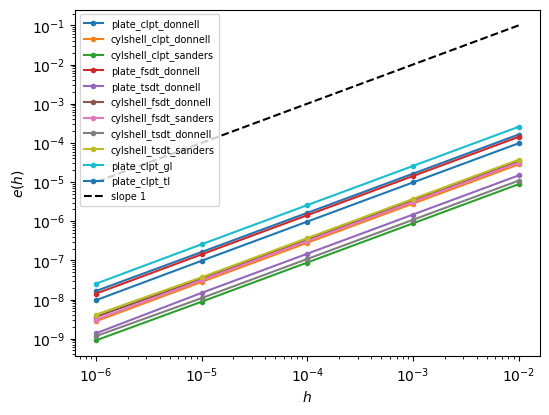

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, slope of $e(h)$ | 0.999185 | 1 | -8.15e-04 | second-order remainder of the Taylor expansion |
| `cylshell_clpt_donnell`, slope of $e(h)$ | 1.00087 | 1 | +8.65e-04 | second-order remainder of the Taylor expansion |
| `cylshell_clpt_sanders`, slope of $e(h)$ | 0.997582 | 1 | -2.42e-03 | second-order remainder of the Taylor expansion |
| `plate_fsdt_donnell`, slope of $e(h)$ | 1.00058 | 1 | +5.83e-04 | second-order remainder of the Taylor expansion |
| `plate_tsdt_donnell`, slope of $e(h)$ | 1.00632 | 1 | +6.32e-03 | second-order remainder of the Taylor expansion |
| `cylshell_fsdt_donnell`, slope of $e(h)$ | 0.994342 | 1 | -5.66e-03 | second-order remainder of the Taylor expansion |
| `cylshell_fsdt_sanders`, slope of $e(h)$ | 1.00144 | 1 | +1.44e-03 | second-order remainder of the Taylor expansion |
| `cylshell_tsdt_donnell`, slope of $e(h)$ | 0.99419 | 1 | -5.81e-03 | second-order remainder of the Taylor expansion |
| `cylshell_tsdt_sanders`, slope of $e(h)$ | 0.991273 | 1 | -8.73e-03 | second-order remainder of the Taylor expansion |
| `plate_clpt_gl`, slope of $e(h)$ | 1.00143 | 1 | +1.43e-03 | second-order remainder of the Taylor expansion |
| `plate_clpt_tl`, slope of $e(h)$ | 1.00153 | 1 | +1.53e-03 | second-order remainder of the Taylor expansion |

In [7]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for model, e in taylor.items():
    ax.loglog(steps, e, 'o-', ms=3, label=model)
ax.loglog(steps, steps/steps[0]*1e-1, 'k--', label='slope 1')
ax.set_xlabel('$h$')
ax.set_ylabel('$e(h)$')
ax.legend(fontsize=7)
plt.show()
rows = [('`%s`, slope of $e(h)$' % model,
         np.polyfit(np.log10(steps), np.log10(e), 1)[0], 1.,
         'second-order remainder of the Taylor expansion')
        for model, e in taylor.items()]
results_table(rows)

The product $\boldsymbol{K}_T \boldsymbol{v}$ is also available without assembling $\boldsymbol{K}_T$, at the cost of one evaluation of the internal force vector, with `Shell.calc_kTv` and `MultiDomain.calc_kTv`.

The methods `calc_fext`, `calc_fint`, `calc_kC` and `calc_kG` of `Shell` and `MultiDomain` have the signatures required by `structsolve.Analysis`. It implements the Newton-Raphson method with load control and the arc-length methods, see [Non-linear static analysis with the arc-length methods](ex_arc_length.ipynb).